In [2]:

"""
EDA Notebook for Hybrid Recommendation System
Purpose: Exploratory Data Analysis using data directly loaded from S3
Data: ratings.csv, movies.csv, tags.csv (MovieLens)
"""
# Dependencies and Configs
import sagemaker
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
# Initialize SageMaker session and define S3 paths
sess = sagemaker.Session()
bucket = "my-ml-hybrid-recsys-bucket"
prefix = "recommender"
s3_input_path = f"s3://{bucket}/{prefix}/input-data/"

# Load all three datasets directly from S3
ratings = pd.read_csv(f"{s3_input_path}ratings.csv")
movies = pd.read_csv(f"{s3_input_path}movies.csv")
tags = pd.read_csv(f"{s3_input_path}tags.csv")

# Basic dataset inspection
print("=== Dataset Shapes ===")
print(f"Ratings: {ratings.shape}")
print(f"Movies: {movies.shape}")
print(f"Tags: {tags.shape}")

print("\n=== Ratings Sample ===")
print(ratings.head())

print("\n=== Movies Sample ===")
print(movies.head())

print("\n=== Tags Sample ===")
print(tags.head())



=== Dataset Shapes ===
Ratings: (100836, 4)
Movies: (9742, 3)
Tags: (3683, 4)

=== Ratings Sample ===
   userId  movieId  rating  timestamp
0       1        1     4.0  964982703
1       1        3     4.0  964981247
2       1        6     4.0  964982224
3       1       47     5.0  964983815
4       1       50     5.0  964982931

=== Movies Sample ===
   movieId                               title  \
0        1                    Toy Story (1995)   
1        2                      Jumanji (1995)   
2        3             Grumpier Old Men (1995)   
3        4            Waiting to Exhale (1995)   
4        5  Father of the Bride Part II (1995)   

                                        genres  
0  Adventure|Animation|Children|Comedy|Fantasy  
1                   Adventure|Children|Fantasy  
2                               Comedy|Romance  
3                         Comedy|Drama|Romance  
4                                       Comedy  

=== Tags Sample ===
   userId  movieId             

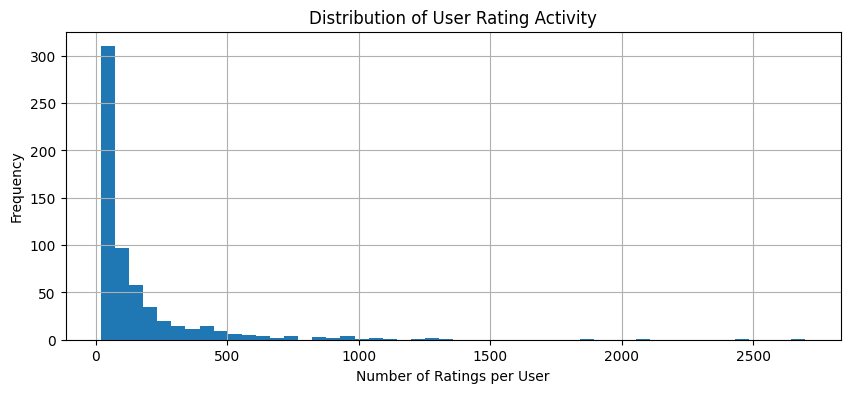

In [5]:
# User activity distribution
plt.figure(figsize=(10, 4))
ratings["userId"].value_counts().hist(bins=50)
plt.title("Distribution of User Rating Activity")
plt.xlabel("Number of Ratings per User")
plt.ylabel("Frequency")
plt.show()



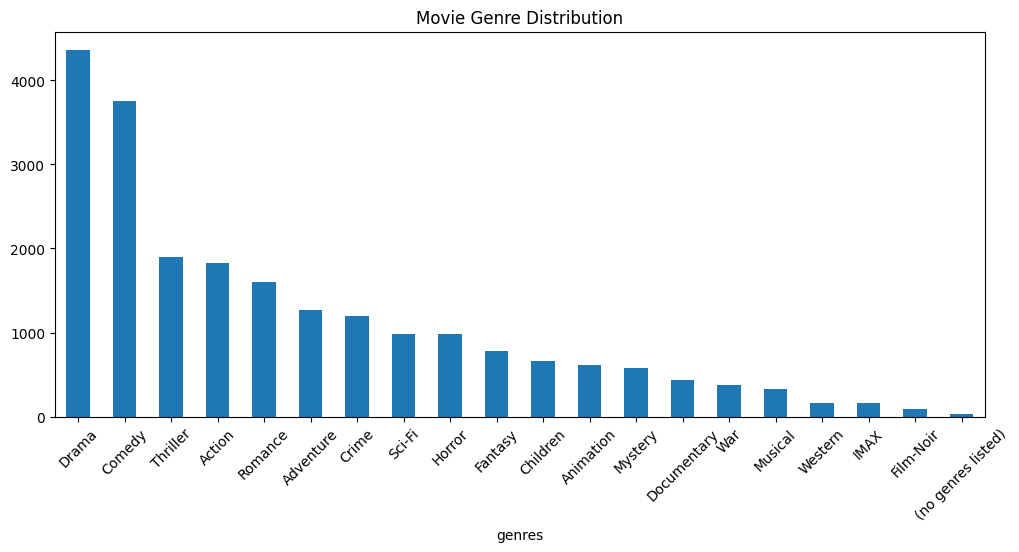

In [6]:
# Movie genre distribution
genres_split = movies["genres"].str.split("|").explode()
plt.figure(figsize=(12, 5))
genres_split.value_counts().plot(kind="bar")
plt.title("Movie Genre Distribution")
plt.xticks(rotation=45)
plt.show()



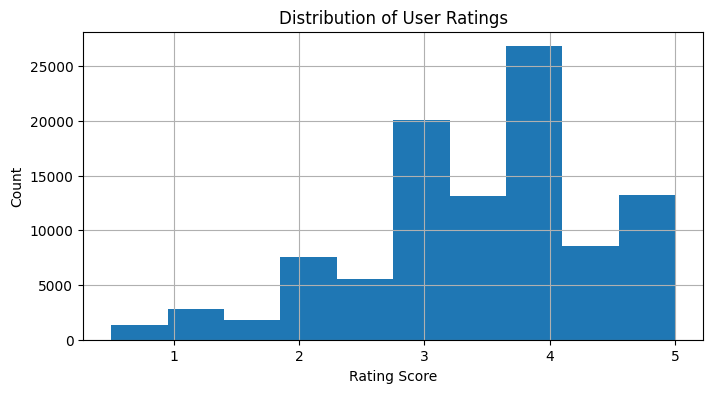

In [7]:
# Overall rating distribution
plt.figure(figsize=(8, 4))
ratings["rating"].hist(bins=10)
plt.title("Distribution of User Ratings")
plt.xlabel("Rating Score")
plt.ylabel("Count")
plt.show()



In [8]:
# Tag frequency analysis
print("\n=== Top 10 Most Frequent Tags ===")
print(tags["tag"].value_counts().head(10))


=== Top 10 Most Frequent Tags ===
tag
In Netflix queue     131
atmospheric           36
thought-provoking     24
superhero             24
surreal               23
funny                 23
Disney                23
religion              22
dark comedy           21
sci-fi                21
Name: count, dtype: int64
